In [1]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [2]:
import pandas as pd
import numpy as np

from sklearn.metrics import mean_absolute_error, root_mean_squared_error
import lightgbm as lgb
import joblib

df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/ADS_Project/data/processed/feature_data.csv")
df["date"] = pd.to_datetime(df["date"])

df.head()


,date,store,item,sales,day,month,year,day_of_week,is_weekend,sales_lag_1,sales_lag_7,sales_lag_14,sales_lag_30,rolling_mean_7,rolling_mean_14
0,2013-01-31,1,1,13,31,1,2013,3,0,9.0,8.0,16.0,13.0,10.285714,10.857143
1,2013-02-01,1,1,11,1,2,2013,4,0,13.0,14.0,7.0,11.0,11.000000,10.642857
2,2013-02-02,1,1,21,2,2,2013,5,1,11.0,12.0,18.0,14.0,10.571429,10.928571
3,2013-02-03,1,1,15,3,2,2013,6,1,21.0,12.0,15.0,13.0,11.857143,11.142857
4,2013-02-04,1,1,14,4,2,2013,0,0,15.0,11.0,8.0,10.0,12.285714,11.142857


In [3]:
# Define cutoff date (last 3 months for validation)
cutoff_date = df["date"].max() - pd.DateOffset(months=3)

train_df = df[df["date"] < cutoff_date]
val_df   = df[df["date"] >= cutoff_date]

print(train_df.shape, val_df.shape)


(851500, 15) (46500, 15)


In [4]:
TARGET = "sales"

FEATURES = [
    col for col in df.columns
    if col not in ["sales", "date"]
]

X_train = train_df[FEATURES]
y_train = train_df[TARGET]

X_val = val_df[FEATURES]
y_val = val_df[TARGET]


In [5]:
model = lgb.LGBMRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=8,
    num_leaves=64,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    verbose=50
)

model.fit(
    X_train,
    y_train,
    eval_set=[(X_val, y_val)],
    eval_metric="rmse"
)


[LightGBM] [Debug] Dataset::GetMultiBinFromAllFeatures: sparse rate 0.065741
[LightGBM] [Debug] init for col-wise cost 0.000159 seconds, init for row-wise cost 0.152852 seconds
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.214488 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1393
[LightGBM] [Info] Number of data points in the train set: 851500, number of used features: 13
[LightGBM] [Info] Start training from score 52.512674
[LightGBM] [Debug] Trained a tree with leaves = 64 and depth = 7
[LightGBM] [Debug] Trained a tree with leaves = 64 and depth = 8
[LightGBM] [Debug] Trained a tree with leaves = 64 and depth = 8
[LightGBM] [Debug] Trained a tree with leaves = 64 and depth = 8
[LightGBM] [Debug] Trained a tree with leaves = 64 and depth = 8
[LightGBM] [Debug] Trained a tree with leaves = 64 and depth = 8
[LightGBM] [Debug] Trained a tree with leaves = 64 and depth = 7
[LightGBM] [Debug] Train

LGBMRegressor(colsample_bytree=0.8, learning_rate=0.05, max_depth=8,
              n_estimators=300, num_leaves=64, random_state=42, subsample=0.8,
              verbose=50)

In [6]:
y_pred = model.predict(X_val)

mae = mean_absolute_error(y_val, y_pred)
rmse = root_mean_squared_error(y_val, y_pred)
mape = np.mean(np.abs((y_val - y_pred) / y_val)) * 100

print(f"MAE  : {mae:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"MAPE : {mape:.2f}%")


MAE  : 6.00
RMSE : 7.77
MAPE : 13.15%


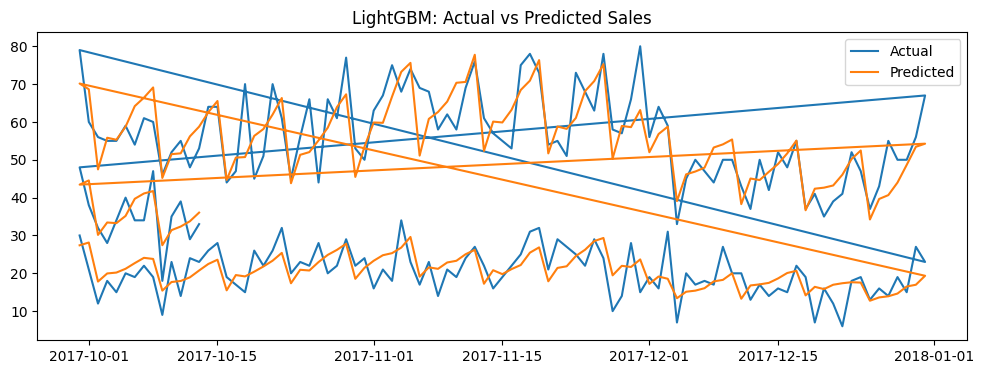

In [7]:
import matplotlib.pyplot as plt

sample_val = val_df.iloc[:200]

plt.figure(figsize=(12,4))
plt.plot(sample_val["date"], sample_val["sales"], label="Actual")
plt.plot(sample_val["date"], model.predict(sample_val[FEATURES]), label="Predicted")
plt.legend()
plt.title("LightGBM: Actual vs Predicted Sales")
plt.show()


In [8]:
joblib.dump(model, "/content/drive/MyDrive/Colab Notebooks/ADS_Project/models/lightgbm_model.pkl")


['/content/drive/MyDrive/Colab Notebooks/ADS_Project/models/lightgbm_model.pkl']